In [13]:
import pandas as pd
import pandas as pd, numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

In [46]:
df=pd.read_csv("../Datasets/unsw_train.csv")
df_t=pd.read_csv("../Datasets/unsw_test.csv")

In [47]:
df_id = df.drop(columns=["id","label"])
df_t_id = df_t.drop(columns=["id","label"])

print("Train :", df_id.shape)
print("Test :", df_t_id.shape)

# Vérification des colonnes
diff = 0

if len(df_id.columns) == len(df_t_id.columns):
    for i in range(len(df_id.columns)):
        if df_id.columns[i] != df_t_id.columns[i]:
            diff += 1
else:
    diff = abs(len(df_id.columns) - len(df_t_id.columns))

print("Colonnes différentes entre train et test :", diff)

display(df_id.head(3))
print(df_id.dtypes.value_counts())

Train : (82332, 43)
Test : (175341, 43)
Colonnes différentes entre train et test : 0


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat
0,0.000011,udp,-,INT,2,0,496,0,90909.0902,254,...,1,1,2,0,0,0,1,2,0,Normal
1,0.000008,udp,-,INT,2,0,1762,0,125000.0003,254,...,1,1,2,0,0,0,1,2,0,Normal
2,0.000005,udp,-,INT,2,0,1068,0,200000.0051,254,...,1,1,3,0,0,0,1,3,0,Normal


int64      28
float64    11
object      4
Name: count, dtype: int64


In [50]:
SEUIL_CONST = 0.97   # une valeur dominante au-delà de ce taux = quasi constante
SEUIL_CORR = 0.9    # corrélation au-delà de laquelle on supprime une des deux colonnes

y = df["label"]
X = df.drop(columns=["id", "attack_cat", "label"])

# Colonnes quasi constantes
quasi_const = [c for c in X.columns
               if X[c].value_counts(normalize=True).iloc[0] > SEUIL_CONST]
X = X.drop(columns=quasi_const)
print("Quasi constantes :", quasi_const)

#Utilité de chaque feature numérique pour prédire label
num = X.select_dtypes("number")
mi = pd.Series(mutual_info_classif(num, y, random_state=42), index=num.columns)

# Paires corrélées (Pearson), de la plus forte à la plus faible
corr = num.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = (upper.stack()
              .loc[lambda s: s > SEUIL_CORR]
              .sort_values(ascending=False))
print("Nbrs de paires corrélées :", len(pairs))

# Pour chaque paire, on supprime la moins informative des deux
dropped = set()
for (a, b), r in pairs.items():
    if a in dropped or b in dropped:
        continue                      # paire déjà résolue
    loser = a if mi[a] < mi[b] else b
    dropped.add(loser)
    print(f"{a} vs {b} (r={r:.2f}) -> on supprime {loser}")

X = X.drop(columns=list(dropped))

print("\nQuasi constantes :", quasi_const)
print("Corrélées supprimées :", sorted(dropped))
print("Features restantes :", X.shape[1])
print(list(X.columns))

Quasi constantes : ['is_ftp_login', 'ct_ftp_cmd', 'is_sm_ips_ports']
Nbrs de paires corrélées : 15
dbytes vs dloss (r=1.00) -> on supprime dloss
sbytes vs sloss (r=1.00) -> on supprime sloss
ct_srv_src vs ct_srv_dst (r=0.98) -> on supprime ct_srv_src
dpkts vs dbytes (r=0.98) -> on supprime dpkts
spkts vs sbytes (r=0.97) -> on supprime spkts
ct_dst_ltm vs ct_src_dport_ltm (r=0.96) -> on supprime ct_dst_ltm
swin vs dwin (r=0.96) -> on supprime dwin
ct_dst_src_ltm vs ct_srv_dst (r=0.94) -> on supprime ct_dst_src_ltm
tcprtt vs synack (r=0.94) -> on supprime tcprtt
ct_src_dport_ltm vs ct_src_ltm (r=0.93) -> on supprime ct_src_ltm
ct_src_dport_ltm vs ct_dst_sport_ltm (r=0.91) -> on supprime ct_src_dport_ltm

Quasi constantes : ['is_ftp_login', 'ct_ftp_cmd', 'is_sm_ips_ports']
Corrélées supprimées : ['ct_dst_ltm', 'ct_dst_src_ltm', 'ct_src_dport_ltm', 'ct_src_ltm', 'ct_srv_src', 'dloss', 'dpkts', 'dwin', 'sloss', 'spkts', 'tcprtt']
Features restantes : 28
['dur', 'proto', 'service', 'state', 

### RandomForest V1

82332 -> 53946
groupes contradictoires : 6
['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst']
Features restantes : 39

                    Accuracy  Precision  Recall      F1  ROC-AUC
Majoritaire (val)    0.6340     0.0000  0.0000  0.0000   0.5000
RF train             1.0000     1.0000  1.0000  1.0000   1.0000
RF validation        0.9655     0.9589  0.9463  0.9526   0.9946
RF test              0.9654     0.9602  0.9446  0.9523   0.9933
validation: VN=5010  FP=120  FN=159  VP=2803
test: VN=5014  FP=116  FN=164  VP=2798


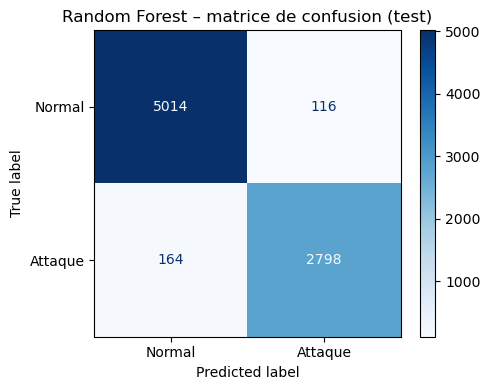

num__ct_dst_src_ltm    0.1408
num__ct_state_ttl      0.0757
num__ct_srv_dst        0.0707
num__sttl              0.0671
num__sbytes            0.0374
num__ct_srv_src        0.0360
num__smean             0.0359
num__tcprtt            0.0347
num__dload             0.0345
num__synack            0.0292
dtype: float64


In [38]:
# 1. Train / validation / test (70 / 15 / 15)
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42)

# 2. Jeux de données
features = X.columns
print(list(X.columns))
print("Features restantes :", X.shape[1])
cat_cols = [c for c in ["proto", "service", "state"] if c in features]
num_cols = [c for c in features if c not in cat_cols]
X_train, y_train = train_df[features], train_df["label"]
X_val,   y_val   = val_df[features],   val_df["label"]
X_test,  y_test  = test_df[features],  test_df["label"]

# 3. Modèles : baseline majoritaire + Random Forest
prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01), cat_cols),  # regroupe les protos rares
    ("num", "passthrough", num_cols),
])
dummy = Pipeline([("prep", prep), ("model", DummyClassifier(strategy="most_frequent"))])
rf = Pipeline([("prep", prep),
               ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))])
dummy.fit(X_train, y_train)
rf.fit(X_train, y_train)

# 4. Évaluation
def evaluate(model, X_, y_):
    pred = model.predict(X_)
    proba = model.predict_proba(X_)[:, 1]
    return {"Accuracy": accuracy_score(y_, pred),
            "Precision": precision_score(y_, pred, zero_division=0),
            "Recall": recall_score(y_, pred),
            "F1": f1_score(y_, pred),
            "ROC-AUC": roc_auc_score(y_, proba)}

results = pd.DataFrame({
    "Majoritaire (val)": evaluate(dummy, X_val, y_val),
    "RF train": evaluate(rf, X_train, y_train),
    "RF validation": evaluate(rf, X_val, y_val),
    "RF test": evaluate(rf, X_test, y_test),
}).T.round(4)
print("\n", results)

for name, X_, y_ in [("validation", X_val, y_val), ("test", X_test, y_test)]:
    tn, fp, fn, tp = confusion_matrix(y_, rf.predict(X_)).ravel()
    print(f"{name}: VN={tn}  FP={fp}  FN={fn}  VP={tp}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test,
                                      display_labels=["Normal", "Attaque"], cmap="Blues", ax=ax)
ax.set_title("Random Forest – matrice de confusion (test)")
plt.tight_layout(); plt.show()

names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
print(imp.head(10).round(4))

### RandomForest V2 : correction du dataleakage (doublons)

Apres vérification nous avons remarqué la présence de doublosn dans le dataset.

In [54]:
feat_cols = [c for c in df.columns if c not in ["id", "attack_cat", "label"]]

# a) Doublons dans le dataset brut
n_dup = df.duplicated(subset=feat_cols).sum()
print(f"df brut : {len(df)} lignes, {n_dup} doublons ({n_dup/len(df):.1%})")

# b) Même features mais labels contradictoires
conf = df.groupby(feat_cols, dropna=False)["label"].nunique()
print("Groupes à labels contradictoires :", (conf > 1).sum())

# c) Après dédoublonnage
df_dedup = df.drop_duplicates(subset=feat_cols).reset_index(drop=True)
print("Doublons restants dans df_dedup :", df_dedup.duplicated(subset=feat_cols).sum())

df brut : 82332 lignes, 28386 doublons (34.5%)
Groupes à labels contradictoires : 6
Doublons restants dans df_dedup : 0


On a donc ici un data leakage avec des doublons entre notre train,validate et test. Un dédoublonnage a donc été fait.

Ensuite nous avons adapté notre choix des features pour que celui-ci se fasse essentiellement sur le train_split sans doublons. 
Ici on crée une fct pour simplifié les prochaines étapes

In [80]:
SEUIL_CONST = 0.97
SEUIL_CORR = 0.9

def select_features(data, seuil_const=SEUIL_CONST,
                    seuil_corr=SEUIL_CORR, verbose=True):
    y = data["label"]
    X = data.drop(columns=["id", "attack_cat", "label"])

    # 1. Colonnes quasi constantes (sauf celles protégées)
    quasi_const = [c for c in X.columns
                   if X[c].value_counts(normalize=True).iloc[0] > seuil_const]
    X = X.drop(columns=quasi_const)

    # 2. Information mutuelle de chaque feature numérique avec le label
    num = X.select_dtypes("number")
    mi = pd.Series(mutual_info_classif(num, y, random_state=42), index=num.columns)

    # 3. Paires corrélées, de la plus forte à la plus faible
    corr = num.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    pairs = upper.stack().loc[lambda s: s > seuil_corr].sort_values(ascending=False)

    # 4. Pour chaque paire, on supprime la moins informative (jamais une colonne protégée)
    dropped = set()
    for (a, b), r in pairs.items():
        if a in dropped or b in dropped:
            continue
        else:
            loser = a if mi[a] < mi[b] else b
        dropped.add(loser)
        if verbose:
            print(f"{a} vs {b} (r={r:.2f}) -> on supprime {loser}")

    feats = [c for c in X.columns if c not in dropped]
    if verbose:
        print("Quasi constantes :", quasi_const)
        print("Features restantes :", len(feats))
    return feats

val  avec copie dans train : 0
test avec copie dans train : 0
dbytes vs dloss (r=1.00) -> on supprime dloss
sbytes vs sloss (r=1.00) -> on supprime sloss
dpkts vs dbytes (r=0.98) -> on supprime dpkts
spkts vs sbytes (r=0.96) -> on supprime spkts
swin vs dwin (r=0.95) -> on supprime swin
tcprtt vs synack (r=0.94) -> on supprime synack
ct_srv_src vs ct_srv_dst (r=0.92) -> on supprime ct_srv_src
Quasi constantes : ['is_ftp_login', 'ct_ftp_cmd', 'is_sm_ips_ports']
Features restantes : 32
Features retenues : 32
['dur', 'proto', 'service', 'state', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst']

                    Accuracy  Precision  Recall      F1  ROC-AUC
Majoritaire (val)    0.6340     0.0000  0.0000  0.0

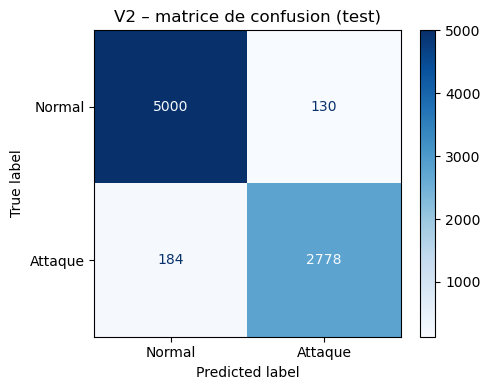

num__ct_dst_src_ltm    0.1361
num__sttl              0.0897
num__ct_srv_dst        0.0813
num__ct_state_ttl      0.0597
num__dload             0.0464
num__sbytes            0.0457
num__tcprtt            0.0433
num__smean             0.0424
num__dbytes            0.0347
num__rate              0.0330
dtype: float64


In [82]:
# 1. Split sur les données dédoublonnées (70 / 15 / 15)
train_df, temp_df = train_test_split(df_dedup, test_size=0.30, stratify=df_dedup["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42)

# On vérifie que pas de doublons dans val et test
h = lambda d: pd.util.hash_pandas_object(d[feat_cols], index=False)
s_train = set(h(train_df))
print("val  avec copie dans train :", h(val_df).isin(s_train).sum())
print("test avec copie dans train :", h(test_df).isin(s_train).sum())

# 2. Sélection des features sur le TRAIN uniquement
features = select_features(train_df)
print("Features retenues :", len(features))
print(features)

cat_cols = [c for c in ["proto", "service", "state"] if c in features]
num_cols = [c for c in features if c not in cat_cols]
X_train, y_train = train_df[features], train_df["label"]
X_val,   y_val   = val_df[features],   val_df["label"]
X_test,  y_test  = test_df[features],  test_df["label"]

# 3. Modèles
prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01), cat_cols),
    ("num", "passthrough", num_cols),
])
dummy = Pipeline([("prep", prep), ("model", DummyClassifier(strategy="most_frequent"))])
rf = Pipeline([("prep", prep),
               ("model", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))])
dummy.fit(X_train, y_train)
rf.fit(X_train, y_train)

# 4. Évaluation
def evaluate(model, X_, y_):
    pred = model.predict(X_)
    proba = model.predict_proba(X_)[:, 1]
    return {"Accuracy": accuracy_score(y_, pred),
            "Precision": precision_score(y_, pred, zero_division=0),
            "Recall": recall_score(y_, pred),
            "F1": f1_score(y_, pred),
            "ROC-AUC": roc_auc_score(y_, proba)}

results = pd.DataFrame({
    "Majoritaire (val)": evaluate(dummy, X_val, y_val),
    "RF train": evaluate(rf, X_train, y_train),
    "RF validation": evaluate(rf, X_val, y_val),
    "RF test": evaluate(rf, X_test, y_test),
}).T.round(4)
print("\n", results)

for name, X_, y_ in [("validation", X_val, y_val), ("test", X_test, y_test)]:
    tn, fp, fn, tp = confusion_matrix(y_, rf.predict(X_)).ravel()
    print(f"{name}: VN={tn}  FP={fp}  FN={fn}  VP={tp}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test,
                                      display_labels=["Normal", "Attaque"], cmap="Blues", ax=ax)
ax.set_title("V2 – matrice de confusion (test)")
plt.tight_layout(); plt.show()

names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
print(imp.head(10).round(4))